# Project: Breast Cancer (SEER) & FUTURE-AI

This notebook prepares the data **identically for all groups**, so results stay comparable even if you choose different FUTURE-AI criteria. It contains:

1. Dataset import
2. Label creation (5-year Overall Survival)
3. Train/test split and Cross-Validation
4. Data pre-processing

**From here on, the project is yours.** You will need to add:
- **EDA** — explore the dataset: distributions, subgroups, any data quality issues, relationships between variables and with the outcome
- **Machine Learning pipeline** — feature engineering/selection, model choice and comparison, hyperparameter tuning (using the Cross-Validation already set up), final evaluation on the test set
- **FUTURE-AI assessment** — Fairness, Universality, Traceability, Usability, Robustness, Explainability and design a concrete analysis for each

**Important rule**: the test set created in this notebook must be used **only for the final evaluation** of the chosen model. To compare models/hyperparameters during development, use Cross-Validation on the train set — never the test set, otherwise the final results will be optimistically biased ("procedural" data leakage).



## 1. Dataset import

In [6]:
import pandas as pd
import numpy as np

SEED = 42
np.random.seed(SEED)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

### Load the dataset in VS Code or Google Colab

The notebook first looks for the CSV in the project folder or current working directory. If it is not found locally and the notebook is running in Colab, it mounts Google Drive and uses the configured Drive path.


In [7]:
from pathlib import Path

CSV_NAME = "Copia di SEER Breast Cancer Dataset .csv"
PROJECT_DIR = Path(r"C:\Progetti\neuroengineering_course\progetto")
LOCAL_PATHS = [PROJECT_DIR / CSV_NAME, Path.cwd() / CSV_NAME]

# Prefer the local CSV when it is available, including in VS Code.
dataset_path = next((path for path in LOCAL_PATHS if path.is_file()), None)

if dataset_path is None:
    try:
        from google.colab import drive
    except ImportError as exc:
        raise FileNotFoundError(
            "CSV not found locally. Place it in the project folder or update PROJECT_DIR."
        ) from exc

    # This branch runs in Colab when the CSV is not present locally.
    drive.mount("/content/drive")
    dataset_path = Path("/content/drive/MyDrive/progettoneuro") / CSV_NAME

if not dataset_path.is_file():
    raise FileNotFoundError(f"CSV not found at {dataset_path}. Check its location.")

print(f"Dataset path: {dataset_path}")


Dataset path: C:\Progetti\neuroengineering_course\progetto\Copia di SEER Breast Cancer Dataset .csv


In [8]:
# Read the dataset selected in the previous cell.
df = pd.read_csv(dataset_path)

print("Raw shape:", df.shape)
df.head()


Raw shape: (4024, 16)


,Age,Race,Marital Status,Unnamed: 3,T Stage,N Stage,6th Stage,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,43,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),NaN,T2,N3,IIIC,Moderately differentiated; Grade II,Regional,40,Positive,Positive,19,11,1,Alive
1,47,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),NaN,T2,N2,IIIA,Moderately differentiated; Grade II,Regional,45,Positive,Positive,25,9,2,Alive
2,67,White,Married (including common law),NaN,T2,N1,IIB,Poorly differentiated; Grade III,Regional,25,Positive,Positive,4,1,2,Dead
3,46,White,Divorced,NaN,T1,N1,IIA,Moderately differentiated; Grade II,Regional,19,Positive,Positive,26,1,2,Dead
4,63,White,Married (including common law),NaN,T2,N2,IIIA,Moderately differentiated; Grade II,Regional,35,Positive,Positive,21,5,3,Dead


The file contains two small technical artifacts that must be removed before any analysis (these are not part of the EDA you will do — they are defects of the CSV file, not of the clinical content):
- an unnamed, completely empty column;
- 1 duplicate row.

In [9]:
df = df.drop(columns=["Unnamed: 3"]).copy() #to remove empty colums
df.columns = [c.strip() for c in df.columns]  # removes accidental whitespace in column names
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after minimal cleaning:", df.shape)
assert df.isna().sum().sum() == 0, "there should be no missing values left" #there are no any missing value
df.head()

Shape after minimal cleaning: (4023, 15)


,Age,Race,Marital Status,T Stage,N Stage,6th Stage,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,43,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),T2,N3,IIIC,Moderately differentiated; Grade II,Regional,40,Positive,Positive,19,11,1,Alive
1,47,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),T2,N2,IIIA,Moderately differentiated; Grade II,Regional,45,Positive,Positive,25,9,2,Alive
2,67,White,Married (including common law),T2,N1,IIB,Poorly differentiated; Grade III,Regional,25,Positive,Positive,4,1,2,Dead
3,46,White,Divorced,T1,N1,IIA,Moderately differentiated; Grade II,Regional,19,Positive,Positive,26,1,2,Dead
4,63,White,Married (including common law),T2,N2,IIIA,Moderately differentiated; Grade II,Regional,35,Positive,Positive,21,5,3,Dead


### Data dictionary

| Column | Meaning |
|---|---|
| `Age` | Age at diagnosis (years) |
| `Race` | Ethnicity (SEER categories: White / Black / Other) |
| `Marital Status` | Marital status at diagnosis |
| `T Stage` | Extent of the primary tumor (AJCC), T1 (small) → T4 (extensive) |
| `N Stage` | Regional lymph node involvement, N1 → N3 (increasing) |
| `6th Stage` | Overall AJCC 6th edition stage (combines T, N, and metastatic status) |
| `Grade` | Histologic differentiation grade of the tumor (I = well differentiated → IV = anaplastic) |
| `A Stage` | Regional (localized/loco-regional) vs Distant (metastatic) |
| `Tumor Size` | Tumor diameter (mm) |
| `Estrogen Status` / `Progesterone Status` | Hormone receptor status (Positive/Negative) |
| `Regional Node Examined` | No. of lymph nodes surgically examined |
| `Reginol Node Positive` | No. of lymph nodes found positive (with metastasis) |
| `Survival Months` | Months of observed follow-up |
| `Status` | Status at the end of follow-up: Alive (alive/censored) or Dead (deceased) |

`Survival Months` and `Status` are **only** used to build the label — they are not legitimate model features (using them would be data leakage: they would use the very outcome you're trying to predict).

## 2. Label creation — 5-year Overall Survival

The task is: **predict whether a patient will have died within 5 years (60 months) of diagnosis**, using only clinico-pathological information available at diagnosis/initial staging.

Not all patients can be used: anyone still "Alive" with a shorter follow-up than 60 months is still under observation — their 5-year outcome is not known (censoring), and they must be excluded rather than forced into one of the two classes.

- **label = 1** (death within 5 years): `Status == "Dead"` and `Survival Months < 60`
- **label = 0** (survives to 5 years): `Survival Months >= 60` (regardless of what happens afterwards)
- **excluded**: `Status == "Alive"` and `Survival Months < 60` (unknown outcome)


In [10]:
HORIZON = 60  # months

survived = df[df["Survival Months"] >= HORIZON].copy()
survived["label"] = 0

died_early = df[(df["Status"] == "Dead") & (df["Survival Months"] < HORIZON)].copy()
died_early["label"] = 1

excluded = df[(df["Status"] == "Alive") & (df["Survival Months"] < HORIZON)]

task_df = pd.concat([survived, died_early], ignore_index=True)

print(f"Evaluable patients: {len(task_df)}  |  excluded (censored before 5 years): {len(excluded)} "
      f"({len(excluded)/len(df)*100:.1f}% of the original cohort)")
print(task_df["label"].value_counts(normalize=True).rename("share").round(3))

Evaluable patients: 3270  |  excluded (censored before 5 years): 753 (18.7% of the original cohort)
label
0    0.863
1    0.137
Name: share, dtype: float64


## 3. Train/test split and Cross-Validation

Stratified split (keeps the same proportion of events in train and test) with a fixed seed, so all groups start from the same data.

The columns `Survival Months`, `Status` (used to build the label) and the `label` itself are separated out from `X`. **`6th Stage` is not removed here**: it's one of the questions you should ask yourselves during EDA and feature engineering (hint: check its relationship with `T Stage`/`N Stage`/`A Stage`).

In [11]:
from sklearn.model_selection import train_test_split, StratifiedKFold

LEAKAGE_COLS = ["Survival Months", "Status", "label"]  # do NOT use as a feature

X = task_df.drop(columns=LEAKAGE_COLS)
y = task_df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Event prevalence (label=1) — train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

Train: (2452, 13)  Test: (818, 13)
Event prevalence (label=1) — train: 0.137  test: 0.137


In [12]:
# Cross-Validation to use for comparing models/hyperparameters ON THE TRAIN SET
# (never on the test set: that is reserved for final evaluation)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

## 4. Data pre-processing

The preprocessor standardizes numerical features, applies ordinal encoding to `T Stage`, `N Stage` and `Grade`, and one-hot encodes the remaining categorical features. The clinical order is specified explicitly. Ordinal codes start at 0, so `T1`, `N1` and Grade I receive 0; higher levels receive increasing integers. Unexpected ordinal categories raise an error so they can be reviewed.

Use the preprocessor as the first step of every scikit-learn `Pipeline`. Fit it only on training data: separately within each cross-validation fold or on the final training set. This prevents information from the test set or validation fold from leaking into model development.


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

NUM_COLS = ["Age", "Tumor Size", "Regional Node Examined", "Reginol Node Positive"]
ORD_COLS = ["T Stage", "N Stage", "Grade"]  # These categories have a meaningful clinical order.
CAT_COLS = ["Race", "Marital Status", "6th Stage", "A Stage",
            "Estrogen Status", "Progesterone Status"]  # Keep these as separate categories.

# Fix the clinical order explicitly, so the encoder does not infer it alphabetically.
# OrdinalEncoder assigns 0 to the first level, 1 to the second, and so on.
ORD_CATEGORIES = [
    ["T1", "T2", "T3", "T4"],  # Primary tumor stage, from T1 to T4.
    ["N1", "N2", "N3"],  # Regional lymph node stage, from N1 to N3.
    ["Well differentiated; Grade I", "Moderately differentiated; Grade II",
     "Poorly differentiated; Grade III", "Undifferentiated; anaplastic; Grade IV"],
]
assert set(NUM_COLS) | set(ORD_COLS) | set(CAT_COLS) == set(X.columns)  # Check feature coverage.

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_COLS),  # Put numeric features on comparable scales.
        ("ord", OrdinalEncoder(categories=ORD_CATEGORIES), ORD_COLS),  # Preserve clinical order.
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),  # Avoid imposing an order on these categories.
    ])


In [14]:
# sanity check: the preprocessor works and produces the expected output
preprocessor = make_preprocessor()
X_train_transformed = preprocessor.fit_transform(X_train)
print("X_train shape after preprocessing:", X_train_transformed.shape)
print("Example of generated feature names:", list(preprocessor.get_feature_names_out()[:5]), "...")

X_train shape after preprocessing: (2452, 26)
Example of generated feature names: ['num__Age', 'num__Tumor Size', 'num__Regional Node Examined', 'num__Reginol Node Positive', 'ord__T Stage'] ...


**Modeling note:** Ordinal encoding preserves the order of T Stage, N Stage and Grade, but in a linear model a one-step increase is assumed to have the same effect across levels. This is a modeling assumption to consider when interpreting results. The remaining categorical features use one-hot encoding without dropping a reference level; consider a reference category if readily interpretable linear-model coefficients are needed.


## From here on, it's up to you

You have available: `df` (cleaned dataset), `task_df` (with the label), `X_train`, `X_test`, `y_train`, `y_test`, the `cv` object, and `make_preprocessor()`.

Project checklist:
- [ ] **EDA**: explore `df`/`task_df` — distributions, subgroups, any dataset issues or limitations, relationships between clinical variables and the outcome
- [ ] **Feature engineering / selection**: which columns to keep? is there redundancy? do outliers or transformations need handling?
- [ ] **ML pipeline**: build one or more `Pipeline`s (`preprocessor` → optional selection → model), compare models/hyperparameters with `cv` on the train set, then evaluate **once** on the test set
- [ ] **Metrics**: justify your choice of evaluation metrics (watch out for class imbalance — accuracy alone is misleading)
- [ ] **FUTURE-AI**: choose 2 criteria among Fairness, Universality, Traceability, Usability, Robustness, Explainability, and design a quantitative and/or qualitative analysis for each, justifying your choice


In [ ]:
# EDA: relazione tra lo stadio complessivo e gli stadi componenti
# Usiamo solo X_train: il test set resta riservato alla valutazione finale.
for col in ["T Stage", "N Stage", "A Stage"]:
    print(f"\n{col} vs 6th Stage — percentuali per riga")
    display(
        pd.crosstab(
            X_train[col],
            X_train["6th Stage"],
            normalize="index"
        ).round(2)
    )



T Stage vs 6th Stage — percentuali per riga


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
T Stage,,,,,
T1,0.82,0.00,0.12,0.00,0.06
T2,0.00,0.62,0.24,0.00,0.14
T3,0.00,0.00,0.78,0.00,0.22
T4,0.00,0.00,0.00,0.63,0.37



N Stage vs 6th Stage — percentuali per riga


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
N Stage,,,,,
N1,0.48,0.4,0.10,0.01,0.0
N2,0.00,0.0,0.95,0.05,0.0
N3,0.00,0.0,0.00,0.00,1.0



A Stage vs 6th Stage — percentuali per riga


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
A Stage,,,,,
Distant,0.00,0.00,0.00,0.33,0.67
Regional,0.33,0.28,0.27,0.01,0.12


## 5. Exploratory Data Analysis (EDA)

This section describes the training set before model development. Class **0** means observed survival of at least 60 months; class **1** means death from any cause before 60 months. Patients recorded alive with shorter follow-up were excluded because their five-year outcome is unknown. This exclusion may affect how representative the analyzed cohort is.

All comparisons below use `X_train` and `y_train`; the held-out test set remains reserved for final model evaluation. Group differences are descriptive associations, not evidence of causation.


In [15]:
import matplotlib.pyplot as plt
from IPython.display import display
import textwrap

# Keep the outcome aligned with its original training-set rows.
assert X_train.index.equals(y_train.index)
eda_train = X_train.copy()
eda_train["label"] = y_train

# Reuse the feature groups defined in the preprocessing section.
EDA_NUM_COLS = NUM_COLS
EDA_CAT_COLS = ORD_COLS + CAT_COLS
assert set(EDA_NUM_COLS + EDA_CAT_COLS) == set(X_train.columns)

print(f"Cleaned cohort: {len(df):,} patients")
print(f"Excluded because of censoring before 5 years: {len(excluded):,}")
print(f"Evaluable cohort: {len(task_df):,} patients")
print(f"Training set analyzed below: {len(eda_train):,} patients")


Cleaned cohort: 4,023 patients
Excluded because of censoring before 5 years: 753
Evaluable cohort: 3,270 patients
Training set analyzed below: 2,452 patients


### 5.1 Outcome Distribution

The classes are imbalanced. The table and chart show how many training patients are in each outcome group. The positive class is death before five years. This information helps us interpret later comparisons and select evaluation metrics.


,Patients,Training set (%)
0: Survived at least 5 years,2115,86.3
1: Died before 5 years,337,13.7


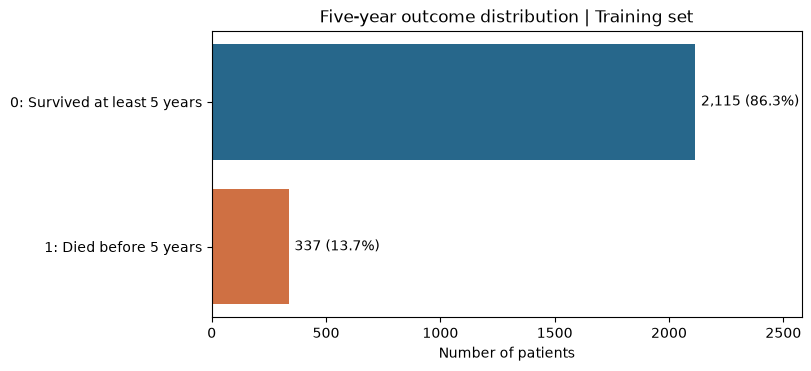

In [16]:
outcome_counts = eda_train["label"].value_counts().reindex([0, 1], fill_value=0)
outcome_table = pd.DataFrame({
    "Patients": outcome_counts,
    "Training set (%)": (100 * outcome_counts / len(eda_train)).round(1),
})
outcome_table.index = ["0: Survived at least 5 years", "1: Died before 5 years"]
display(outcome_table)

fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
bars = ax.barh(outcome_table.index, outcome_counts.to_numpy(), color=["#27678b", "#cf7043"])
ax.invert_yaxis()
ax.set_title("Five-year outcome distribution | Training set")
ax.set_xlabel("Number of patients")
ax.set_xlim(0, max(outcome_counts) * 1.22)
for bar, count in zip(bars, outcome_counts):
    ax.text(count + len(eda_train) * 0.01, bar.get_y() + bar.get_height() / 2,
            f"{count:,} ({count / len(eda_train):.1%})", va="center")
plt.show()


## 6. Numerical Variables

The four numerical features describe age, tumor size and regional lymph nodes. Summary statistics show center, spread and observed range. Extreme observations may be clinically plausible; they should not be removed automatically.

### 6.1 Numerical Summary and Outcome Comparison

The first table summarizes the whole training set. The second compares the median of each feature between the two outcome groups; medians alone do not show the full distribution or establish a causal relationship.


In [ ]:
numeric_summary = eda_train[EDA_NUM_COLS].describe().T.rename(columns={
    "count": "Patients", "mean": "Mean", "std": "Std. deviation",
    "min": "Minimum", "25%": "25th percentile", "50%": "Median",
    "75%": "75th percentile", "max": "Maximum",
})
display(numeric_summary.round(2))

median_by_outcome = eda_train.groupby("label")[EDA_NUM_COLS].median().T
median_by_outcome.columns = ["Class 0: survived ≥5 years", "Class 1: died <5 years"]
print("Median by outcome group")
display(median_by_outcome.round(2))


,Patients,Mean,Std. deviation,Minimum,25th percentile,Median,75th percentile,Maximum
Age,2452.0,54.15,8.99,30.0,47.0,55.0,62.0,69.0
Tumor Size,2452.0,30.76,21.31,1.0,16.0,25.0,38.0,140.0
Regional Node Examined,2452.0,14.42,8.09,1.0,9.0,14.0,19.0,60.0
Reginol Node Positive,2452.0,4.27,5.21,1.0,1.0,2.0,5.0,46.0


Median by outcome group


,Class 0: survived ≥5 years,Class 1: died <5 years
Age,54.0,57.0
Tumor Size,23.0,33.0
Regional Node Examined,14.0,14.0
Reginol Node Positive,2.0,5.0


### 6.2 Histograms: Distribution of Each Numerical Feature

Each histogram shows the number of training patients in each range. The panels use the original units, making it easier to see skewness, common values and long tails.


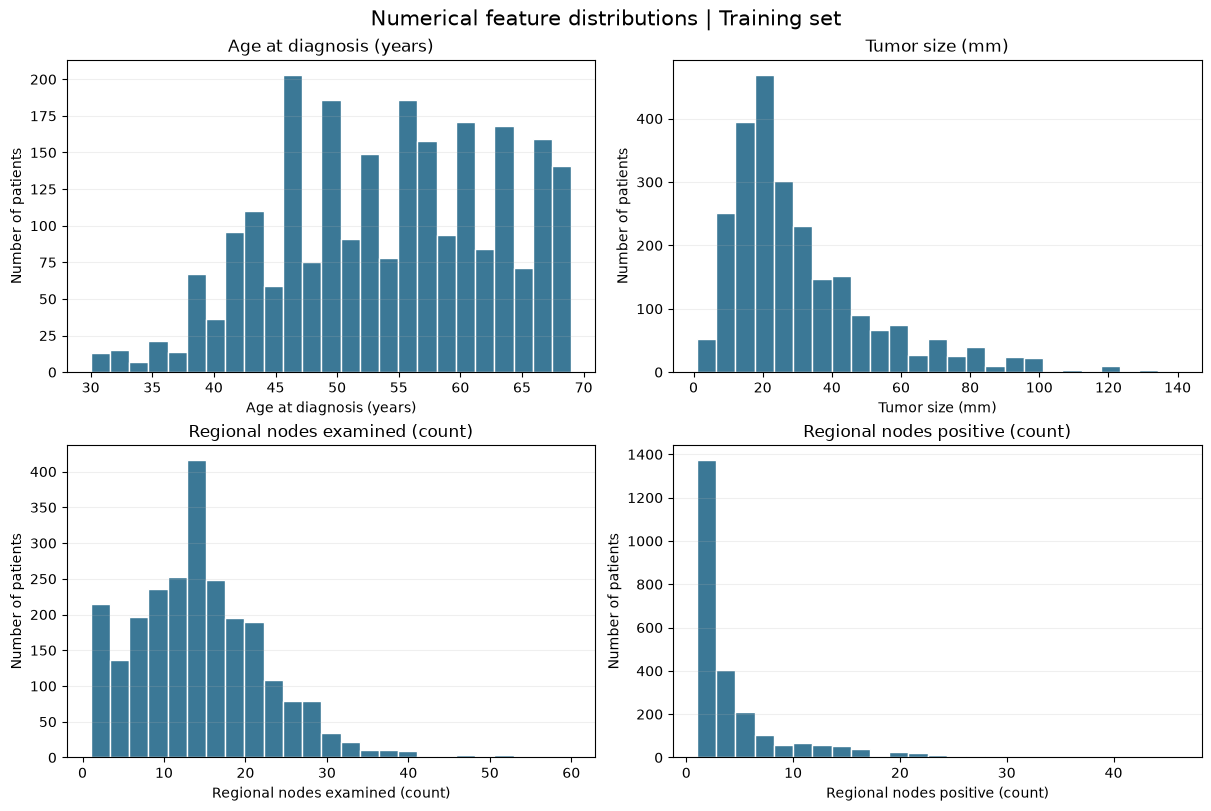

In [ ]:
NUM_LABELS = {
    "Age": "Age at diagnosis (years)",
    "Tumor Size": "Tumor size (mm)",
    "Regional Node Examined": "Regional nodes examined (count)",
    "Reginol Node Positive": "Regional nodes positive (count)",
}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
for ax, col in zip(axes.flat, EDA_NUM_COLS):
    ax.hist(eda_train[col].dropna(), bins=25, color="#3b7896", edgecolor="white")
    ax.set_title(NUM_LABELS[col])
    ax.set_xlabel(NUM_LABELS[col])
    ax.set_ylabel("Number of patients")
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Numerical feature distributions | Training set", fontsize=15)
plt.show()


### 6.3 Box Plots: Numerical Features by Outcome

The center line is the median and the box spans the middle 50% of each group. Whiskers and individual points show the spread using the standard box-plot rule; points beyond the whiskers are not necessarily data errors. Compare both the overlap and the sample sizes, as the outcome groups are unequal.


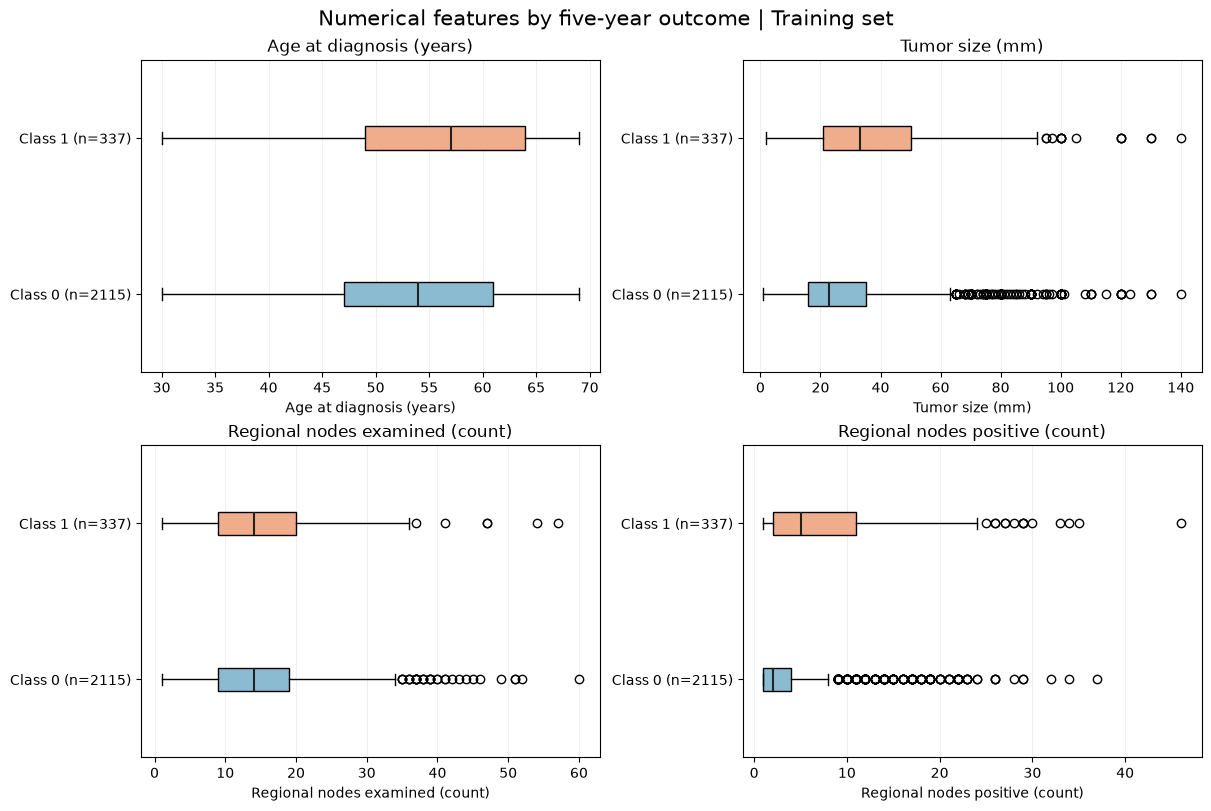

In [ ]:
from inspect import signature

fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
for ax, col in zip(axes.flat, EDA_NUM_COLS):
    groups = [eda_train.loc[eda_train["label"] == label, col].dropna() for label in (0, 1)]
    # Matplotlib renamed the horizontal-orientation option in version 3.10.
    orientation = {"orientation": "horizontal"} if "orientation" in signature(ax.boxplot).parameters else {"vert": False}
    boxes = ax.boxplot(groups, patch_artist=True, **orientation,
                       medianprops={"color": "#222222", "linewidth": 1.5})
    for patch, color in zip(boxes["boxes"], ["#8bbbd0", "#efad8b"]):
        patch.set_facecolor(color)
    ax.set_yticks([1, 2], [f"Class 0 (n={len(groups[0])})", f"Class 1 (n={len(groups[1])})"])
    ax.set_title(NUM_LABELS[col])
    ax.set_xlabel(NUM_LABELS[col])
    ax.grid(axis="x", alpha=0.2)
fig.suptitle("Numerical features by five-year outcome | Training set", fontsize=15)
plt.show()


### 6.4 Basic Data-Quality Checks

Check missing values and whether the number of positive nodes exceeds the number examined. A passing check does not prove every observation is correct; it only addresses these specific conditions.


In [ ]:
missing_by_feature = eda_train[X_train.columns].isna().sum().rename("Missing values")
display(missing_by_feature.to_frame())
node_inconsistencies = (eda_train["Reginol Node Positive"] > eda_train["Regional Node Examined"]).sum()
print(f"Patients with more positive nodes than examined: {node_inconsistencies}")


,Missing values
Age,0
Race,0
Marital Status,0
T Stage,0
N Stage,0
6th Stage,0
Grade,0
A Stage,0
Tumor Size,0
Estrogen Status,0


Patients with more positive nodes than examined: 0


## 7. Categorical Variables

For each variable, the table and chart show the number of training patients and the percentage who died before five years **within that category**. The dashed line marks the overall event percentage in the training set. Percentages from small groups, such as Grade IV, should be interpreted cautiously.

These comparisons are descriptive. They do not adjust for other clinical or social variables and do not identify the cause of group differences.


In [17]:
# Keep clinically ordered categories in their meaningful order in tables and plots.
CATEGORY_ORDER = {
    "T Stage": ["T1", "T2", "T3", "T4"],
    "N Stage": ["N1", "N2", "N3"],
    "6th Stage": ["IIA", "IIB", "IIIA", "IIIB", "IIIC"],
    "Grade": ["Well differentiated; Grade I", "Moderately differentiated; Grade II",
              "Poorly differentiated; Grade III", "Undifferentiated; anaplastic; Grade IV"],
}

def show_categorical_eda(column):
    # Calculate counts and the event proportion within each category.
    table = eda_train.groupby(column, dropna=False)["label"].agg(
        Patients="size", Events="sum", event_rate="mean"
    )
    if column in CATEGORY_ORDER:
        ordered = [value for value in CATEGORY_ORDER[column] if value in table.index]
        ordered += [value for value in table.index if value not in ordered]
        table = table.loc[ordered]
    else:
        table = table.sort_values("Patients", ascending=False)
    table["Training set (%)"] = 100 * table["Patients"] / len(eda_train)
    table["Deaths before 5 years (%)"] = 100 * table["event_rate"]
    shown = table[["Patients", "Training set (%)", "Events", "Deaths before 5 years (%)"]]
    display(shown.round(1))

    labels = ["\n".join(textwrap.wrap(str(value), width=30)) for value in table.index]
    positions = np.arange(len(table))
    fig, (ax_count, ax_rate) = plt.subplots(
        1, 2, figsize=(12, max(3.5, len(table) * 0.65 + 2)),
        gridspec_kw={"width_ratios": [1.1, 1]}, layout="constrained"
    )
    ax_count.barh(positions, table["Patients"], color="#3b7896")
    ax_count.set_yticks(positions, labels)
    ax_count.invert_yaxis()
    ax_count.set_xlabel("Number of patients")
    ax_count.set_title("Category size")
    ax_count.set_xlim(0, table["Patients"].max() * 1.22)
    for y, count in zip(positions, table["Patients"]):
        ax_count.text(count + table["Patients"].max() * 0.02, y, f"{count:,}", va="center")

    rates = table["Deaths before 5 years (%)"]
    ax_rate.barh(positions, rates, color="#d27d55")
    ax_rate.set_yticks(positions, [""] * len(positions))
    ax_rate.invert_yaxis()
    overall_rate = 100 * eda_train["label"].mean()
    ax_rate.axvline(overall_rate, color="#333333", linestyle="--", linewidth=1,
                    label=f"Overall: {overall_rate:.1f}%")
    ax_rate.set_xlabel("Deaths before 5 years (%)")
    ax_rate.set_title("Outcome within each category")
    ax_rate.set_xlim(0, max(rates.max(), overall_rate) * 1.30 + 1)
    for y, rate in zip(positions, rates):
        ax_rate.text(rate + 0.7, y, f"{rate:.1f}%", va="center")
    ax_rate.legend(loc="lower right", fontsize=9)
    fig.suptitle(f"{column} | Training set", fontsize=14)
    plt.show()


### 7.1 Race

Compare representation and outcome proportions across the dataset categories. Unequal group sizes and the broad Other category matter for later fairness analysis.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Race,,,,
White,2083,85.0,280,13.4
Black,186,7.6,42,22.6
"Other (American Indian/AK Native, Asian/Pacific Islander)",183,7.5,15,8.2


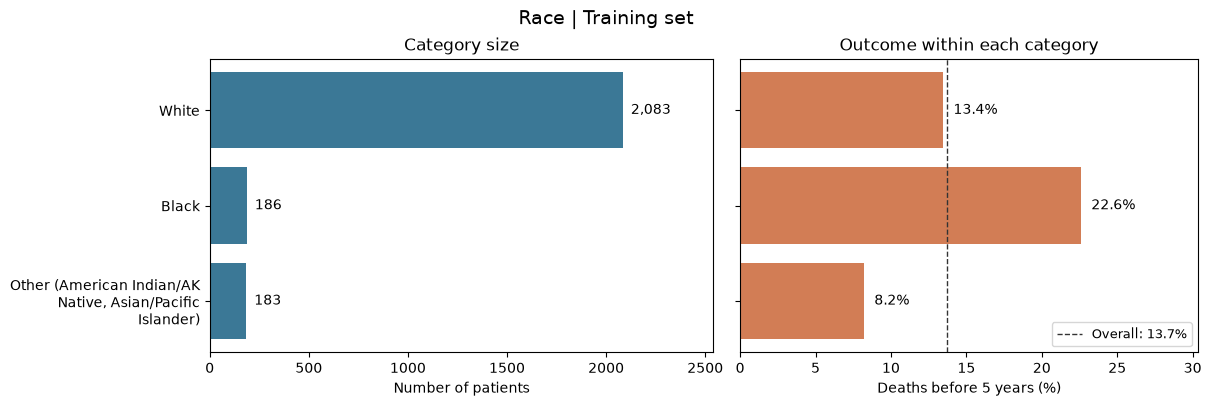

In [ ]:
show_categorical_eda("Race")


### 7.2 Marital Status

Examine the distribution and note groups with few patients. Any association can reflect multiple social and clinical factors.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Marital Status,,,,
Married (including common law),1582,64.5,182,11.5
Single (never married),374,15.3,61,16.3
Divorced,318,13.0,57,17.9
Widowed,148,6.0,28,18.9
Separated,30,1.2,9,30.0


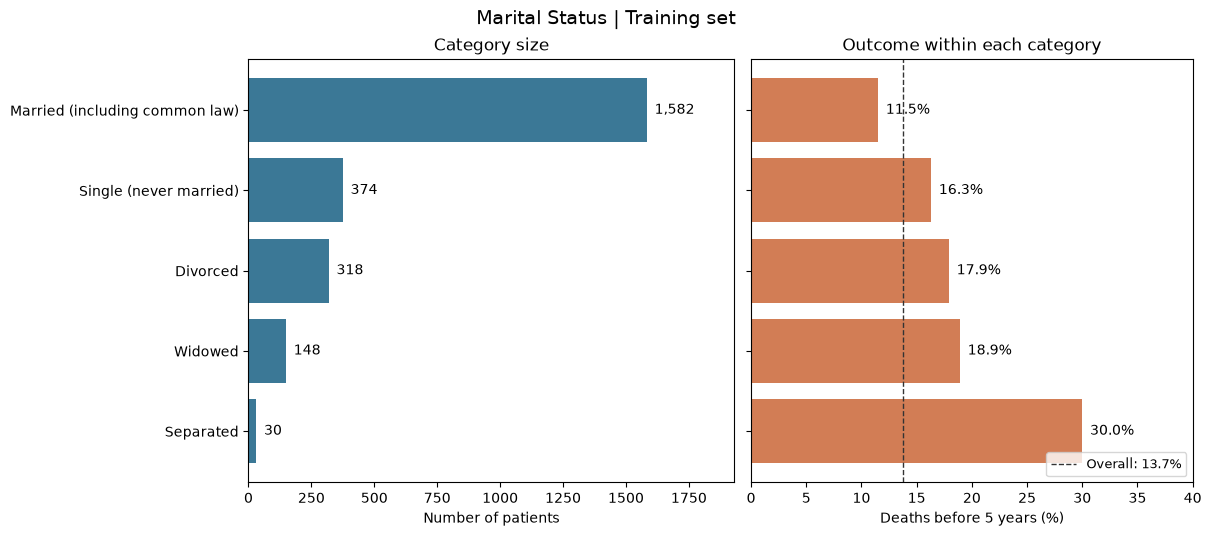

In [ ]:
show_categorical_eda("Marital Status")


### 7.3 T Stage

Compare the ordered primary tumor stages. The percentages describe this training sample, rather than the effect of stage alone.


,Patients,Training set (%),Events,Deaths before 5 years (%)
T Stage,,,,
T1,971,39.6,78,8.0
T2,1068,43.6,164,15.4
T3,340,13.9,69,20.3
T4,73,3.0,26,35.6


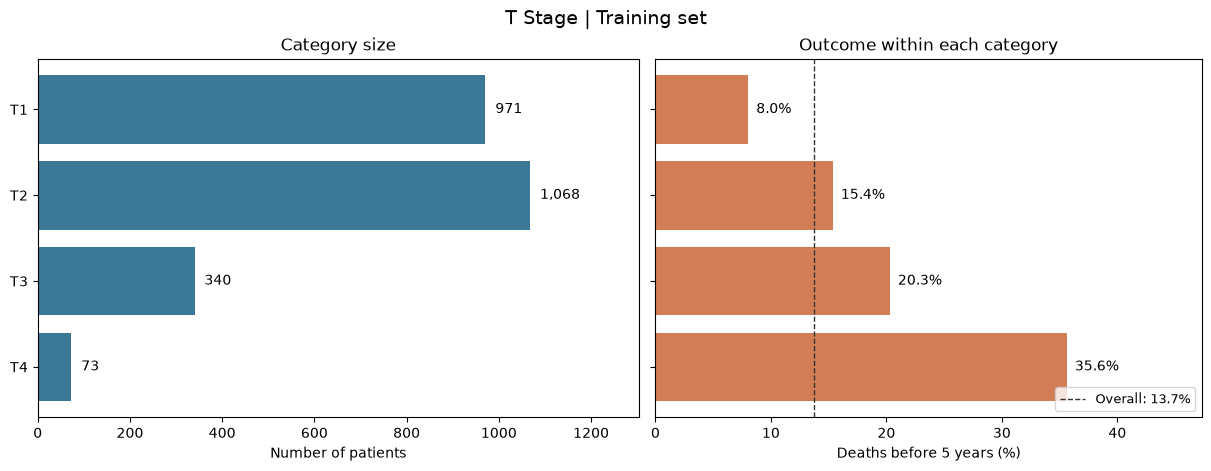

In [ ]:
show_categorical_eda("T Stage")


### 7.4 N Stage

Compare the ordered regional lymph node stages and the size of each group.


,Patients,Training set (%),Events,Deaths before 5 years (%)
N Stage,,,,
N1,1639,66.8,139,8.5
N2,500,20.4,90,18.0
N3,313,12.8,108,34.5


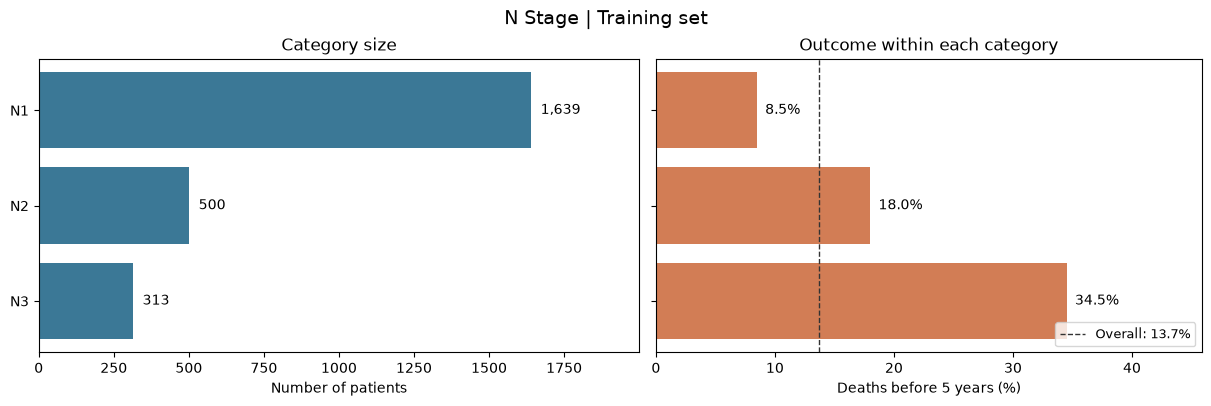

In [ ]:
show_categorical_eda("N Stage")


### 7.5 6th Stage

Inspect the overall stage and consider its overlap with T and N stages. Some categories may have few patients.


,Patients,Training set (%),Events,Deaths before 5 years (%)
6th Stage,,,,
IIA,793,32.3,51,6.4
IIB,661,27.0,63,9.5
IIIA,639,26.1,102,16.0
IIIB,46,1.9,13,28.3
IIIC,313,12.8,108,34.5


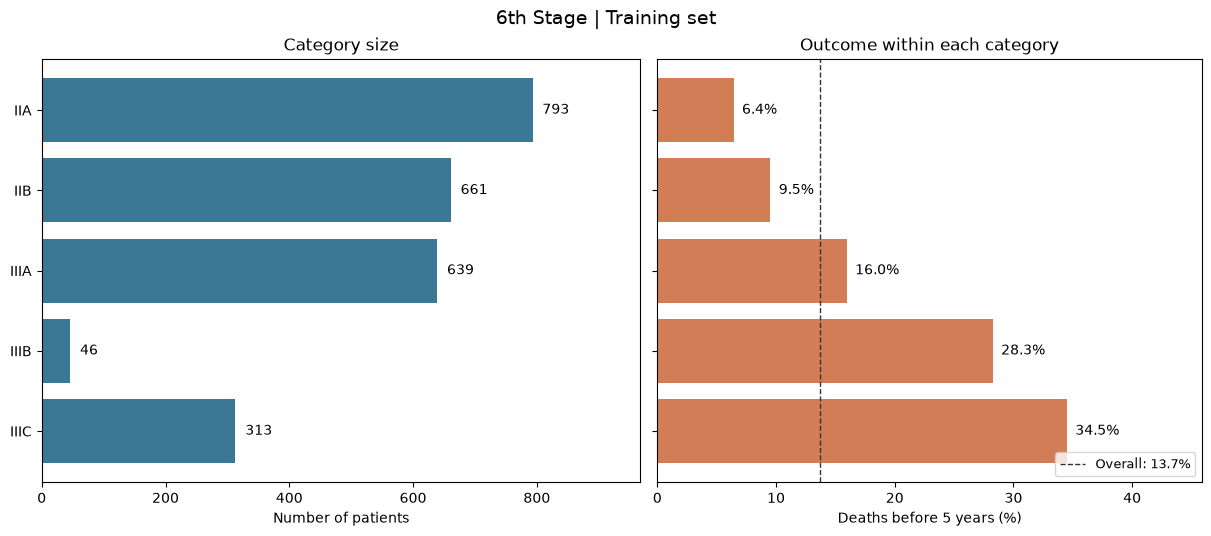

In [ ]:
show_categorical_eda("6th Stage")


### 7.6 Grade

Compare ordered histological grades. Pay particular attention to the small Grade IV group.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Grade,,,,
Well differentiated; Grade I,303,12.4,19,6.3
Moderately differentiated; Grade II,1438,58.6,165,11.5
Poorly differentiated; Grade III,699,28.5,147,21.0
Undifferentiated; anaplastic; Grade IV,12,0.5,6,50.0


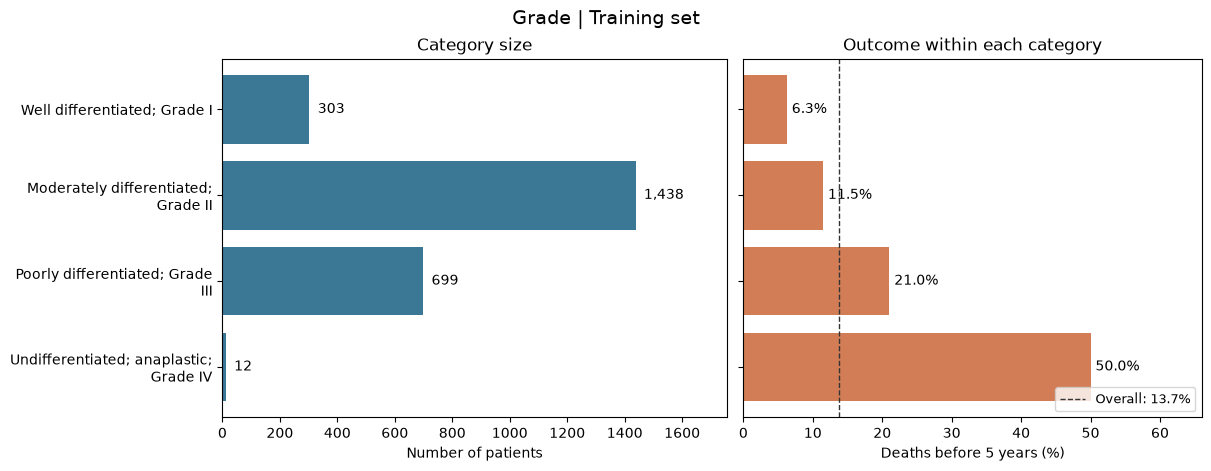

In [ ]:
show_categorical_eda("Grade")


### 7.7 A Stage

Compare Regional and Distant categories, and check group sizes before interpreting their percentages.


,Patients,Training set (%),Events,Deaths before 5 years (%)
A Stage,,,,
Regional,2397,97.8,317,13.2
Distant,55,2.2,20,36.4


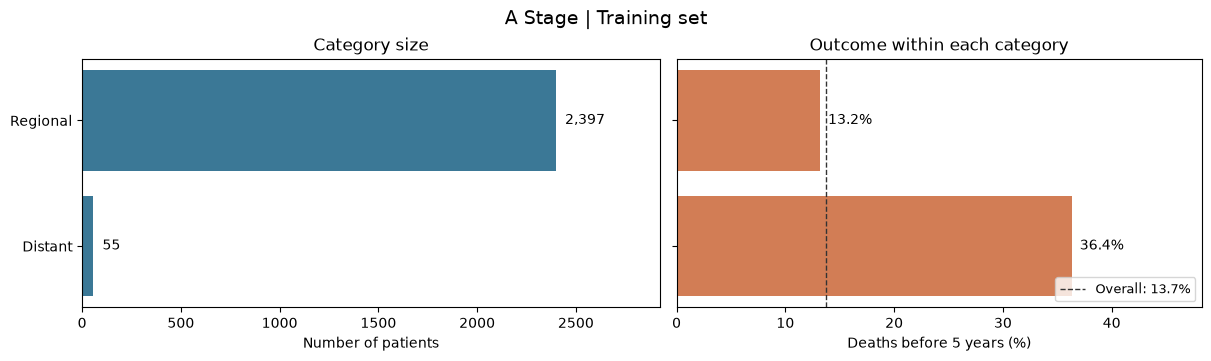

In [ ]:
show_categorical_eda("A Stage")


### 7.8 Estrogen Status

Compare receptor categories. The observed difference is not an adjusted effect of receptor status.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Estrogen Status,,,,
Positive,2267,92.5,268,11.8
Negative,185,7.5,69,37.3


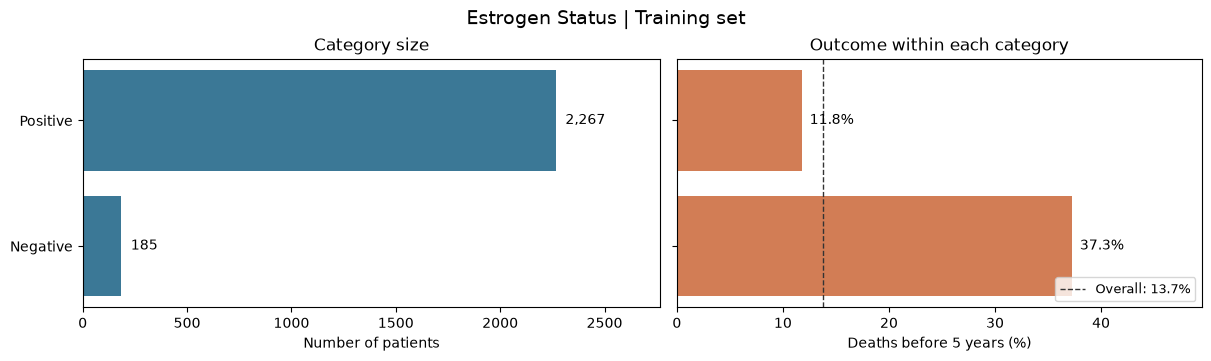

In [ ]:
show_categorical_eda("Estrogen Status")


### 7.9 Progesterone Status

Compare receptor categories and their within-group outcome proportions.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Progesterone Status,,,,
Positive,2007,81.9,209,10.4
Negative,445,18.1,128,28.8


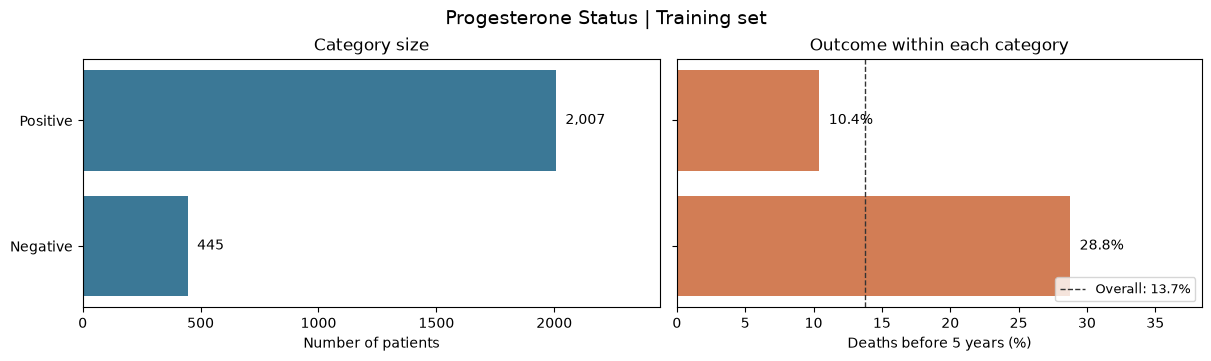

In [ ]:
show_categorical_eda("Progesterone Status")


## 8. EDA Interpretation and Next Decisions

- The class distribution should guide metric selection; accuracy alone can hide poor performance on class 1.
- Review numerical distributions before choosing transformations. Do not remove extreme values without checking their meaning.
- Small categorical groups can have unstable outcome proportions and deserve attention in model evaluation and fairness analysis.
- T Stage, N Stage and Grade have an explicit ordinal encoding; consider the assumptions it imposes for each model.
- 6th Stage is related to other staging variables. Assess feature redundancy during model development.
- Early-censored patients were excluded, and the data may not represent all patient populations. Consider these limits when interpreting results.
